# Notebook 02b — Prepare Camille’s CWF Images and Verify Particle Mapping

This notebook prepares Camille’s externally processed CWF cryo-EM images for the downstream feature-extraction and clustering pipeline. The **main workflow** checks the CWF data and its provenance, connects all **57,107 particles** to the frozen validation assignments from Notebook 01, and creates memory-efficient cropped original and derivative image arrays for Notebook 03.

**Critical ordering fact:** Camille confirmed that the CWF stack retains the **original raw MRC stack order**, **not the STAR row order**. The notebook constructs `outputs/validation/cwf_particle_mapping.csv` using `particle_id` and `stack_index_1based`. CWF images and STAR metadata must **never** be matched by row position alone. The code checks mapping consistency; the underlying CWF ordering is supported by the producer's confirmation, not an independent pixel-level proof.

**Main outputs:** `outputs/cwf_order_provenance.json`, `outputs/validation/cwf_particle_mapping.csv`, and the complete `outputs/camille_cwf_full_crops/` checkpoint (`cropped_original.npy`, `cropped_derivative.npy`, `image_names.npy`, and supporting metadata). Notebook 03 uses the full cropped-image checkpoint; Notebook 09 uses the frozen particle mapping to verify fold correspondence.

**Separate exploratory branch:** The optional `import_external_cwf()` and normalization cells import a selectable subset (currently set to 20,000 particles) and save other CWF checkpoints. **These are not the full 57,107-particle preparation route used for the final analysis.**

**Dependencies:** Requires Camille’s CWF MRC stack, the existing frozen split from Notebook 01, and the project's processing helper modules. Large raw data and generated checkpoints are not included with the notebook.



This notebook is extracted from: expeirment.ipynb (original cells 24–27). The original markdown is kept in all sections.

# 2b Import from Camille's CWF results
## 2b.1. Import Camille's already-cropped CWF results

Optional alternative input for section 4. First report the total number of images in the MRC stack. Set `camille_count` to a positive integer to sample that many images without replacement using `camille_seed`, or to `"all"` to import every image in original stack order. Original stack IDs are preserved. **Do not apply the local circle crop again.** Keep the full imported 64 × 64 arrays and flatten their existing pixels into `cwf_circle_pixels`. The compatibility mask is all True: the MRC has nonzero corners and no recoverable binary circle mask. `cwf_circle_diameter` records the imported grid width for compatibility, not a newly applied circular boundary.

Create the same variables produced by 2.3: `cwf_result`, `cwf_circle_mask`, `cwf_circle_pixels`, `cwf_circle_diameter`, and saved checkpoint paths. Save both files and make the pair available to section 4 immediately. For normalized images, run **2b.1 → 2b.2 → 3 → 4 → 5**, without returning to the local crop.

The input-reference copy is already processed, not raw. Retained local noise controls are resampled onto the same grid but have different processing; section 4 defaults to particles only for this import. Existing local saved checkpoints remain available.


In [1]:
# ADDED: Check whether Notebook 02b's required files exist.
# Reason: Determine whether Camille's CWF results are
# already available before choosing a processing route.
# Memory-safe: No image data is loaded.

from pathlib import Path

# MODIFIED: Locate the project relative to the current Jupyter directory.
# Works when Jupyter starts in ml4ls/ or a subdirectory of it.
working_directory = Path.cwd().resolve()
project_root = next(
    (p for p in (working_directory, *working_directory.parents)
     if (p / "latent_methods.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Cannot find the ML4LS project root (latent_methods.py). "
        "Start Jupyter in the repository or a subdirectory."
    )
base = project_root

files_to_check = [
    "cwf_storage.py",
    "particles_cwf.mrc",
    "latest_cwf_saved.json",
    "cwf_result.npz",
]

for filename in files_to_check:
    matches = list(base.rglob(filename))

    print(f"\n{filename}:")
    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND")


cwf_storage.py:
FOUND: /Users/kr/ml4ls/cwf_storage.py

particles_cwf.mrc:
FOUND: /Users/kr/ml4ls/particles_cwf.mrc

latest_cwf_saved.json:
NOT FOUND

cwf_result.npz:
NOT FOUND


In [3]:
# ADDED: Inspect Camille's existing CWF images.
# Reason: Confirm their dimensions and image count.
# Memory-safe: Uses memory mapping.

import mrcfile
from pathlib import Path

camille_path = project_root / "particles_cwf.mrc"

with mrcfile.mmap(str(camille_path), mode="r") as mrc:
    print("CWF image shape:", mrc.data.shape)
    print("CWF data type:", mrc.data.dtype)
    print("Pixel size:", float(mrc.voxel_size.x), "Å/pixel")

CWF image shape: (57107, 64, 64)
CWF data type: float32
Pixel size: 5.199999809265137 Å/pixel


In [4]:
# ADDED: Inspect Camille's CWF import function.
# Reason: Determine how particle order and identifiers
# are handled before importing the complete dataset.

import sys
import inspect

# MODIFIED: Use your actual helper-module location.
sys.path.insert(0, str(project_root))

from cwf_storage import import_external_cwf

print(inspect.getsource(import_external_cwf))

def import_external_cwf(path, previous_result, count=4000, seed=0):
    """Import a reproducible subset, or count="all" in stack order; retain noise controls.

    External row order has no verified raw/STAR mapping. The input slot therefore
    holds a processed reference copy, NOT a matched raw image.
    """
    import mrcfile
    use_all = isinstance(count, str) and count.lower() == "all"
    if not use_all and (isinstance(count, (bool, np.bool_)) or not isinstance(count, (int, np.integer)) or count < 1):
        raise ValueError('count must be a positive integer or "all"')
    with mrcfile.mmap(str(path), mode="r") as mrc:
        if mrc.data.ndim != 3 or mrc.data.shape[1] != mrc.data.shape[2]:
            raise ValueError("Need a square MRC image stack")
        total = len(mrc.data)
        if not total or (not use_all and count > total):
            raise ValueError(f"Requested {count} images, but the stack contains {total}")
        indices = np.arange(total) if use_all else n

In [5]:
# ADDED: Look for metadata accompanying Camille's CWF stack.
# Reason: Find a reliable mapping between CWF rows and
# the original STAR/MRC particle identifiers.
# Memory-safe: Only lists filenames.

from pathlib import Path

base = project_root

for path in sorted(base.iterdir()):
    if path.is_file() and path.suffix.lower() in {
        ".star", ".csv", ".txt", ".json"
    }:
        print(path.name)

J599_split_0_exported.star
batch0_particle_clusters.csv


In [6]:
# ADDED: Inspect the particle cluster metadata.
# Reason: Check whether this file contains a mapping
# between Camille's CWF images and original particle IDs.
#
# Memory-safe: Read only the first five rows initially.

import pandas as pd
from pathlib import Path

csv_path = project_root / "batch0_particle_clusters.csv"

# ADDED: Display the first five rows.
preview = pd.read_csv(csv_path, nrows=5)

print("Column names:")
print(preview.columns.tolist())

print("\nFirst five rows:")
display(preview)

Column names:
['particle_index', 'rlnImageName', 'pose_cluster', 'view_type', 'side_view_group', 'imaging_cluster', 'fit_to_view_score', 'neighbour_crowding', 'defocus_um', 'half_set']

First five rows:


,particle_index,rlnImageName,pose_cluster,view_type,side_view_group,imaging_cluster,fit_to_view_score,neighbour_crowding,defocus_um,half_set
0,1,000001@J598/restack/batch_0_restacked.mrc,2,side,4.0,3,0.2585,2.251,0.3841,1
1,2,000002@J598/restack/batch_0_restacked.mrc,8,side,5.0,0,0.2317,2.740,2.1596,1
2,3,000003@J598/restack/batch_0_restacked.mrc,3,side,1.0,6,0.3461,2.141,2.1605,2
3,4,000004@J598/restack/batch_0_restacked.mrc,4,end_on,NaN,0,0.5325,2.416,2.2531,1
4,5,000005@J598/restack/batch_0_restacked.mrc,1,oblique,NaN,0,0.4555,1.994,2.2561,1


In [7]:
# ADDED: Verify the cluster CSV against the original STAR file.
# Reason: Check particle coverage and identifier consistency.
# Memory-safe: Reads metadata only, not particle images.

import pandas as pd
import numpy as np
from pathlib import Path

base = project_root

clusters = pd.read_csv(
    base / "batch0_particle_clusters.csv"
)

star_particles = pd.read_csv(
    base / "outputs/lowpass_4wpik5am/particles_original.csv"
)

# ADDED: Compare particle counts.
print("CSV rows:", len(clusters))
print("STAR rows:", len(star_particles))

# ADDED: Check uniqueness.
print(
    "Unique particle indices:",
    clusters["particle_index"].nunique()
)
print(
    "Unique particle names:",
    clusters["rlnImageName"].nunique()
)

# ADDED: Check whether indices cover the original MRC stack.
expected_indices = np.arange(1, 57108)

print(
    "Complete MRC index coverage:",
    np.array_equal(
        np.sort(clusters["particle_index"].to_numpy()),
        expected_indices
    )
)

# ADDED: Check whether the particle identifiers match.
print(
    "Same particle ID set as STAR:",
    set(clusters["rlnImageName"].astype(str))
    == set(star_particles["rlnImageName"].astype(str))
)

CSV rows: 57107
STAR rows: 57107
Unique particle indices: 57107
Unique particle names: 57107
Complete MRC index coverage: True
Same particle ID set as STAR: True


In [8]:
# ADDED: Record the assumed correspondence between
# Camille's CWF stack and the original MRC stack.
#
# IMPORTANT: This is an assumption, not yet verified.
# We must confirm it before relying on the mapping
# for final cross-validation results.

from pathlib import Path
import json

# MODIFIED: Reuse project_root defined in the first code cell.

cwf_provenance = {
    "cwf_file": str(project_root / "particles_cwf.mrc"),
    "original_file": str(project_root / "batch_0_restacked.mrc"),
    "particle_count": 57107,
    "assumed_same_stack_order": True,
    "ordering_verified": False,
    "verification_method": None,
    "notes": "Ordering believed to be preserved; awaiting confirmation."
}

output_path = project_root / "outputs" / "cwf_order_provenance.json"

if output_path.exists():
    raise FileExistsError(f"File already exists: {output_path}")

output_path.write_text(json.dumps(cwf_provenance, indent=2))

print("Saved:", output_path)
print("Ordering verified:", cwf_provenance["ordering_verified"])

Saved: /Users/kr/ml4ls/outputs/cwf_order_provenance.json
Ordering verified: False


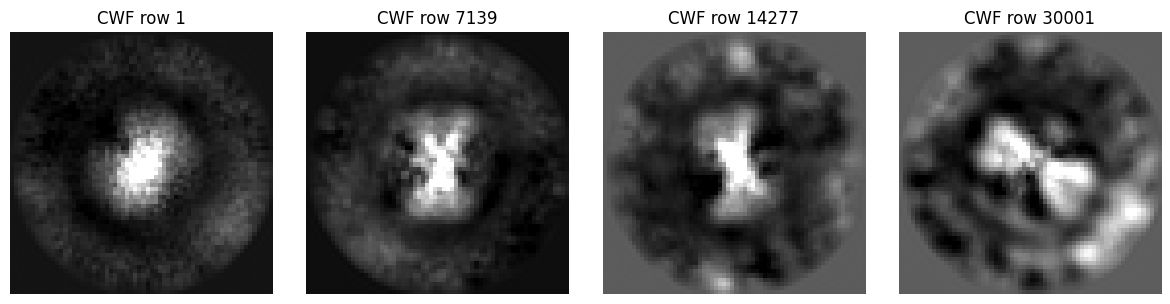

In [9]:
# ADDED: Preview Camille's CWF images directly.
# Reason: Check image quality before importing them.
# Memory-safe: Read only four 64x64 images.

import mrcfile
import numpy as np
import matplotlib.pyplot as plt

camille_path = str(project_root / "particles_cwf.mrc")

# ADDED: Select four different positions in the CWF stack.
# These indices refer to original MRC positions ONLY
# if Camille preserved the same stack ordering.
indices = [0, 7138, 14276, 30000]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

with mrcfile.mmap(camille_path, mode="r") as mrc:
    for ax, idx in zip(axes, indices):

        image = np.asarray(mrc.data[idx], dtype=np.float32)

        # ADDED: Adjust display contrast without altering data.
        vmin, vmax = np.percentile(image, [1, 99])

        ax.imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
        ax.set_title(f"CWF row {idx + 1}")
        ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)


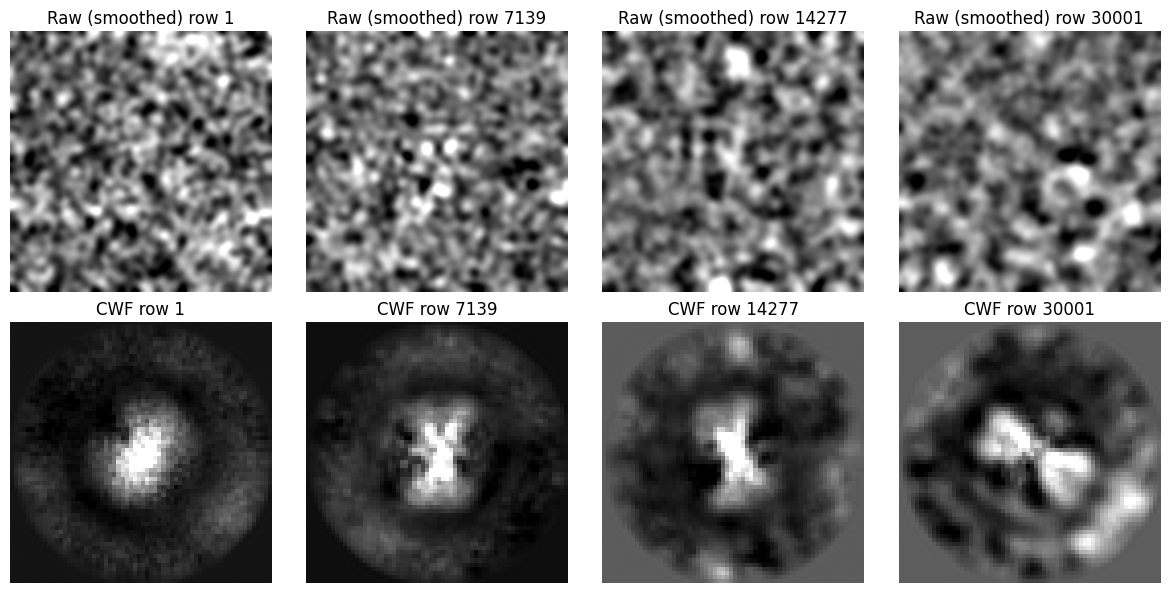

In [10]:
# ADDED: Compare raw and CWF images at identical stack indices.
# Reason: Look for obvious inconsistencies in particle ordering.
# IMPORTANT: Visual similarity does not prove an exact ID mapping.
# Memory-safe: Reads only four images from each stack.

import mrcfile
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, zoom

base = str(project_root) + "/"

indices = [0, 7138, 14276, 30000]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

with mrcfile.mmap(base + "batch_0_restacked.mrc", mode="r") as raw, \
     mrcfile.mmap(base + "particles_cwf.mrc", mode="r") as cwf:

    for col, idx in enumerate(indices):

        # ADDED: Read only the selected raw particle.
        image_raw = np.asarray(raw.data[idx], dtype=np.float32)

        # ADDED: Smooth for visualization only.
        image_raw = gaussian_filter(image_raw, sigma=4)

        # ADDED: Read the corresponding CWF row.
        image_cwf = np.asarray(cwf.data[idx], dtype=np.float32)

        for row, image in enumerate([image_raw, image_cwf]):
            vmin, vmax = np.percentile(image, [1, 99])

            axes[row, col].imshow(
                image,
                cmap="gray",
                vmin=vmin,
                vmax=vmax
            )
            axes[row, col].set_title(
                f"{'Raw (smoothed)' if row == 0 else 'CWF'} "
                f"row {idx + 1}"
            )
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)

In [11]:
# ADDED: Record Camille's confirmation of particle ordering.
# Reason: Preserve verified CWF-to-raw correspondence
# for Notebooks 03–09 and future data integration.

import json
from pathlib import Path

provenance_path = Path(
    str(project_root / "outputs" / "cwf_order_provenance.json")
)

# ORIGINAL: Load our existing provenance record.
with open(provenance_path, "r") as f:
    provenance = json.load(f)

# MODIFIED: Update ordering status based on Camille's confirmation.
provenance["ordering_verified"] = True

# ADDED: Document the source of verification.
provenance["verification_method"] = "Direct confirmation from Camille"
provenance["notes"] = (
    "Camille confirmed that the 57,107 CWF images "
    "preserve the original MRC stack order, "
    "without shuffling or reordering."
)

# ADDED: Save updated provenance.
with open(provenance_path, "w") as f:
    json.dump(provenance, f, indent=2)

print("CWF ordering verification:", provenance["ordering_verified"])
print("Verification method:", provenance["verification_method"])

CWF ordering verification: True
Verification method: Direct confirmation from Camille


In [12]:
# ADDED: Verify CWF-to-STAR mapping using the saved CV manifest.
# Reason: Camille's CWF stack is in original MRC order,
# whereas Notebook 01's processed images are in STAR order.
# Memory-safe: Reads metadata only.

from pathlib import Path
import pandas as pd
import numpy as np

# MODIFIED: Reuse project_root defined in the first code cell.

# ADDED: Load our fixed CV assignments.
cv_manifest = pd.read_csv(
    project_root / "outputs" / "validation"
    / "cv_3fold_with_unknown_test.csv"
)

# ADDED: Prepare mappings between CWF row numbers
# and the original particle identifiers.
cwf_mapping = cv_manifest[
    ["particle_id", "stack_index_1based", "cv_fold"]
].copy()

# MODIFIED: Sort by original MRC stack position,
# not by STAR row position.
cwf_mapping = cwf_mapping.sort_values(
    "stack_index_1based"
).reset_index(drop=True)

# ADDED: Create zero-based CWF row indices.
cwf_mapping["cwf_row_0based"] = (
    cwf_mapping["stack_index_1based"] - 1
)

# ADDED: Verify complete, unique index coverage.
assert np.array_equal(
    cwf_mapping["cwf_row_0based"].to_numpy(),
    np.arange(57107)
)

print("CWF mapping verification: PASSED")

print("\nFirst five CWF rows:")
display(cwf_mapping.head())

print("\nCV group counts:")
print(cwf_mapping["cv_fold"].value_counts().sort_index())

CWF mapping verification: PASSED

First five CWF rows:


,particle_id,stack_index_1based,cv_fold,cwf_row_0based
0,000001@J598/restack/batch_0_restacked.mrc,1,2,0
1,000002@J598/restack/batch_0_restacked.mrc,2,2,1
2,000003@J598/restack/batch_0_restacked.mrc,3,1,2
3,000004@J598/restack/batch_0_restacked.mrc,4,2,3
4,000005@J598/restack/batch_0_restacked.mrc,5,3,4



CV group counts:
cv_fold
0     5711
1    17132
2    17132
3    17132
Name: count, dtype: int64


In [13]:
# ADDED: Save CWF-to-original particle mapping.
# Reason: Preserve particle identities and CV assignments
# for downstream feature extraction and validation.

from pathlib import Path

mapping_path = (
    project_root / "outputs" / "validation"
    / "cwf_particle_mapping.csv"
)

# ADDED: Prevent accidental overwriting.
if mapping_path.exists():
    raise FileExistsError(
        f"Mapping already exists: {mapping_path}"
    )

# ORIGINAL: Reuse the verified mapping from Step 5.15.
cwf_mapping.to_csv(mapping_path, index=False)

print("Mapping saved:", mapping_path)
print("Mapped particles:", len(cwf_mapping))
print("Unique particle IDs:", cwf_mapping["particle_id"].nunique())

Mapping saved: /Users/kr/ml4ls/outputs/validation/cwf_particle_mapping.csv
Mapped particles: 57107
Unique particle IDs: 57107


In [14]:

# ADDED: Memory-efficient access to Camille's CWF images.
# Reason: Avoid loading 57,107 images into RAM.
#
# MODIFIED: Instead of calling import_external_cwf(),
# use the original CWF MRC file directly.
#
# IMPORTANT: This does not yet create the original
# Notebook 02b checkpoint format.

from pathlib import Path
import mrcfile
import numpy as np
import pandas as pd

# MODIFIED: Reuse project_root defined in the first code cell.

camille_path = project_root / "particles_cwf.mrc"

# ADDED: Load the verified particle mapping.
mapping_path = (
    project_root / "outputs" / "validation"
    / "cwf_particle_mapping.csv"
)

cwf_mapping = pd.read_csv(mapping_path)

# ADDED: Open the CWF stack using memory mapping.
# Keep this object open while accessing cwf_images.
cwf_mrc = mrcfile.mmap(str(camille_path), mode="r")

cwf_images = cwf_mrc.data

# ADDED: Verify the dataset.
assert cwf_images.shape == (57107, 64, 64)
assert len(cwf_mapping) == len(cwf_images)

assert np.array_equal(
    cwf_mapping["cwf_row_0based"].to_numpy(),
    np.arange(len(cwf_images))
)

print("CWF images opened successfully!")
print("Shape:", cwf_images.shape)
print("Data type:", cwf_images.dtype)
print("Pixel size:", float(cwf_mrc.voxel_size.x), "Å/pixel")
print("CV groups:", cwf_mapping["cv_fold"].value_counts().sort_index().to_dict())


CWF images opened successfully!
Shape: (57107, 64, 64)
Data type: float32
Pixel size: 5.199999809265137 Å/pixel
CV groups: {0: 5711, 1: 17132, 2: 17132, 3: 17132}


In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# MODIFIED: Reuse the project root from the first code cell.
# The helper modules are in the repository root, not LatentSpace/.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import importlib
import cwf_storage
importlib.reload(cwf_storage)
from cwf_storage import import_external_cwf, save_cwf_result, save_cwf_circles

camille_count = 20000  # Import all 57,107 images; use an integer for a random subset.
camille_seed = 0  # Change to draw a different reproducible random subset.
preview_count = 6
camille_path = project_root / "outputs/cwf_from_camille/particles_cwf.mrc"
# Read the stack shape through mmap; this does not load all image pixels.
import mrcfile
with mrcfile.mmap(str(camille_path), mode="r") as _camille_stack:
    if _camille_stack.data.ndim != 3 or _camille_stack.data.shape[1] != _camille_stack.data.shape[2]:
        raise ValueError("Expected Camille's square-image MRC stack")
    camille_total_count = int(_camille_stack.data.shape[0])
print(f"Camille dataset contains {camille_total_count:,} images in total.")
# Reuse in-memory controls, or read only the noise arrays from the latest saved run.
if "cwf_result" in globals():
    _noise_reference = cwf_result
else:
    import json
    _root = project_root / "outputs"
    _folder = _root / json.loads((_root / "latest_cwf_saved.json").read_text())["directory"]
    with np.load(_folder / "cwf_result.npz", allow_pickle=False) as _saved:
        _noise_reference = {k: _saved[k].copy() for k in ("noise_input", "noise_denoised", "pixel_size_angstrom")}
_camille_result = import_external_cwf(camille_path, _noise_reference, count=camille_count, seed=camille_seed)
cwf_saved_directory = save_cwf_result(_camille_result, project_root / "outputs")
camille_import_result = _camille_result  # Preserve the original input for repeatable 2b.2 runs.
cwf_result = _camille_result
particle_names = cwf_result["image_names"]
cwf_resolution = cwf_result["denoised"].shape[-1]
for _stale in ("cwf_pca_pixels", "cwf_pca_embedding", "cwf_cluster_table"):
    globals().pop(_stale, None)
# Compatibility representation only: preserve every imported pixel, no second crop.
cwf_circle_mask = np.ones(cwf_result["denoised"].shape[1:], dtype=bool)
cwf_circle_diameter = float(cwf_resolution)  # Imported extent, not a new circle.
cwf_circle_pixels = {key: cwf_result[key][:, cwf_circle_mask]
                     for key in ("input", "denoised", "noise_input", "noise_denoised")}
cwf_circle_file = save_cwf_circles(
    cwf_result, cwf_circle_pixels, cwf_circle_mask, cwf_circle_diameter,
)
print(f"Imported {len(particle_names):,} of {camille_total_count:,} images: {cwf_result['denoised'].shape}; {cwf_result['pixel_size_angstrom']} Å/pixel")
print(f"Saved: {cwf_saved_directory}. Both files saved. Continue directly with sections 4 and 5.")
print("Noise controls are from local CWF; PCA defaults to particles only for this checkpoint.")
_camille_preview_count = min(preview_count, len(particle_names))
fig, axes = plt.subplots(1, _camille_preview_count, figsize=(2.5*_camille_preview_count, 3), squeeze=False)
for i, ax in enumerate(axes[0]):
    a = cwf_result["denoised"][i]
    ax.imshow(a, cmap="gray", vmin=np.percentile(a, 1), vmax=np.percentile(a, 99))
    ax.set_title("MRC image " + particle_names[i].split("@", 1)[0]); ax.axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)
del _noise_reference, _camille_result


In [15]:
# ADDED: Inspect the original CWF checkpoint saving function.
# Reason: Determine whether saving all 57,107 CWF images
# requires excessive RAM or creates unnecessary copies.
#
# Memory-safe: Displays source code only.

import inspect
from cwf_storage import save_cwf_result

print(inspect.getsource(save_cwf_result))

def save_cwf_result(result, root):
    arrays = {key: np.asarray(result[key]) for key in KEYS}
    if any(a.ndim != 3 or not np.isfinite(a).all() for a in arrays.values()):
        raise ValueError('Expected finite 3D CWF stacks')
    if arrays['input'].shape != arrays['denoised'].shape or arrays['noise_input'].shape != arrays['noise_denoised'].shape:
        raise ValueError('Input/output dimensions disagree')
    if len(result['image_names']) != len(arrays['denoised']):
        raise ValueError('Particle names do not match image rows')
    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    folder = Path(tempfile.mkdtemp(prefix='cwf_saved_', dir=root))
    _atomic_npz(folder/'cwf_result.npz', **arrays,
                image_names=np.asarray(result['image_names'], dtype=str),
                pixel_size_angstrom=float(result['pixel_size_angstrom']),
                image_shape=np.asarray(arrays['denoised'].shape[1:]),
                run_id=folder.name, schema_version=1,


In [21]:
# ADDED: Inspect Notebook 03's cropping function.
# Reason: Check whether it can process 57,107 images
# in batches without exceeding the 8 GB RAM limit.
# This cell does not process or modify any images.

import inspect
import sys
from pathlib import Path

# ADDED: Make Notebook 03's processing module importable.
# MODIFIED: Reuse project_root defined in the first code cell.

for module_dir in (project_root, project_root / "LatentSpace"):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))

# ADDED: Import the function used in Notebook 03.
from particle_paired import crop_pairs

print(inspect.getsource(crop_pairs))

def crop_pairs(root, images, names, source_checkpoint, source,
               sigma=1., edge_percentile=70., radius_fraction=.35, preserve_edge_strength=True):
    images = np.asarray(images, dtype=np.float32)
    names = np.asarray(names, dtype=str)
    if images.ndim != 3 or not len(images) or not np.isfinite(images).all():
        raise ValueError('Expected a nonempty finite image stack')
    if len(names) != len(images) or len(set(names.tolist())) != len(names): raise ValueError('Invalid image IDs')
    if not np.isfinite(sigma) or sigma <= 0 or not 0 <= edge_percentile <= 100 or not 0 < radius_fraction <= .5:
        raise ValueError('Require sigma > 0, percentile in [0,100], circle radius fraction in (0,.5]')
    if not isinstance(preserve_edge_strength, (bool, np.bool_)): raise ValueError('preserve_edge_strength must be boolean')
    folder, m = _stage(root)
    shape = images.shape[1:]
    y, x = np.indices(shape)
    circle = (y-(shape[0]-1)/2)**2+(x-(shape[1]-1)/2)**2 <= (min

In [22]:
# ADDED: Test original cropping on a small batch.
# Reason: Verify compatibility without processing all 57,107 images.
# This creates a small test checkpoint only.

from pathlib import Path
import numpy as np
from particle_paired import crop_pairs

# ORIGINAL: Use the verified CWF images and mapping.
test_images = np.asarray(cwf_images[:32], dtype=np.float32)

# ADDED: Use the original particle IDs in CWF stack order.
test_names = cwf_mapping["particle_id"].iloc[:32].to_numpy(
    dtype=str
)

# ADDED: Save the small test separately from the full pipeline.
test_root = project_root / "outputs" / "cwf_crop_test"

test_result = crop_pairs(
    root=test_root,
    images=test_images,
    names=test_names,
    source_checkpoint=(project_root / "particles_cwf.mrc"),
    source="camille",
    sigma=1.0,
    edge_percentile=70.0,
    radius_fraction=0.35,
    preserve_edge_strength=False,
)

print("Small cropping test completed.")
print("Output directory:", test_result["directory"])
print("Cropped image shape:", test_result["images"].shape)

Small cropping test completed.
Output directory: /Users/kr/ml4ls/outputs/cwf_crop_test/paired_6r1phtge
Cropped image shape: (32, 64, 64)


In [23]:
# ADDED: Inspect the helper used to save cropped image arrays.
# Reason: Determine how to store the full dataset in batches
# while preserving compatibility with Notebook 03.
# Memory-safe: Displays source code only.

import inspect
import particle_paired

print(inspect.getsource(particle_paired._save))

def _save(folder, manifest, key, array, blocks=None):
    path = folder / (key + '.npy')
    np.save(path, array, allow_pickle=False)
    manifest['files'][key] = str(path)
    if blocks is not None: manifest['blocks'][key] = blocks



In [24]:
# ADDED: Test incremental saving with a memory-mapped .npy file.
# Reason: Prepare a RAM-efficient approach for the full CWF dataset.
# This test does not modify the original processing functions.

from pathlib import Path
import numpy as np

# ADDED: Create a separate test folder.
test_output = (
    (project_root / "outputs")
    / "cwf_memmap_test"
)
test_output.mkdir(parents=True, exist_ok=True)

test_path = test_output / "cropped_original.npy"

# ADDED: Reuse the existing circle-cropping geometry.
height, width = cwf_images.shape[1:]

yy, xx = np.indices((height, width))

circle = (
    (yy - (height - 1) / 2) ** 2
    + (xx - (width - 1) / 2) ** 2
    <= (min(height, width) * 0.35) ** 2
)

# ADDED: Create a disk-backed array for 32 images.
saved_images = np.lib.format.open_memmap(
    test_path,
    mode="w+",
    dtype=np.float32,
    shape=(32, height, width),
)

# ADDED: Process and write a small batch.
batch_size = 8

for start in range(0, 32, batch_size):
    stop = min(start + batch_size, 32)

    # ADDED: Read only the required CWF images.
    batch = np.asarray(
        cwf_images[start:stop],
        dtype=np.float32,
    )

    # ORIGINAL: Apply the same circular mask as crop_pairs().
    saved_images[start:stop] = np.where(
        circle,
        batch,
        0,
    )

# ADDED: Ensure the output is written to disk.
saved_images.flush()

# ADDED: Verify that the saved data matches the original method.
reference = np.where(
    circle,
    np.asarray(cwf_images[:32], dtype=np.float32),
    0,
)

assert np.array_equal(saved_images, reference)

print("Incremental saving: PASSED")
print("Saved shape:", saved_images.shape)
print("Saved file:", test_path)

Incremental saving: PASSED
Saved shape: (32, 64, 64)
Saved file: /Users/kr/ml4ls/outputs/cwf_memmap_test/cropped_original.npy


In [25]:

# ADDED: Memory-efficient implementation of the original crop_pairs
# calculations, using disk-backed arrays and image batches.
# This defines the function only; it does not process the dataset.

from pathlib import Path
import numpy as np
from scipy.ndimage import gaussian_filter

def crop_cwf_batched(images, output_directory, batch_size=32,
                     sigma=1.0, edge_percentile=70.0,
                     radius_fraction=0.35,
                     preserve_edge_strength=False):

    # ADDED: Validate dimensions without copying the full stack.
    if images.ndim != 3 or len(images) == 0:
        raise ValueError("Expected a nonempty 3D image stack.")

    output_directory = Path(output_directory)
    output_directory.mkdir(parents=True, exist_ok=True)

    n, height, width = images.shape

    # ORIGINAL: Preserve crop_pairs() circular mask calculation.
    y, x = np.indices((height, width))
    circle = (
        (y - (height - 1) / 2) ** 2
        + (x - (width - 1) / 2) ** 2
        <= (min(height, width) * radius_fraction) ** 2
    )

    # ADDED: Allocate output on disk instead of allocating full RAM arrays.
    cropped_original = np.lib.format.open_memmap(
        output_directory / "cropped_original.npy",
        mode="w+",
        dtype=np.float32,
        shape=(n, height, width),
    )

    cropped_derivative = np.lib.format.open_memmap(
        output_directory / "cropped_derivative.npy",
        mode="w+",
        dtype=np.float32,
        shape=(n, height, width),
    )

    edge_cutoffs = np.lib.format.open_memmap(
        output_directory / "edge_cutoffs.npy",
        mode="w+",
        dtype=np.float64,
        shape=(n,),
    )

    # ADDED: Process a small number of images at a time.
    for start in range(0, n, batch_size):
        stop = min(start + batch_size, n)

        # ADDED: Read only the current batch into RAM.
        batch = np.asarray(images[start:stop], dtype=np.float32)

        for local_idx, image in enumerate(batch):
            i = start + local_idx

            if not np.isfinite(image).all():
                raise ValueError(f"Nonfinite pixel values in image {i}")

            # ORIGINAL: Preserve Gaussian derivative calculation.
            edge = np.hypot(
                gaussian_filter(image, sigma, order=(1, 0)),
                gaussian_filter(image, sigma, order=(0, 1)),
            )

            # ORIGINAL: Preserve global per-image percentile threshold.
            cutoff = np.percentile(edge, edge_percentile)

            # ORIGINAL: Preserve the selection and derivative logic.
            selected = circle & (edge >= cutoff) & (edge > 0)

            derivative = (
                np.where(selected, edge, 0)
                if preserve_edge_strength
                else selected.astype(np.float32)
            )

            # MODIFIED: Write each result directly to disk.
            cropped_original[i] = np.where(circle, image, 0)
            cropped_derivative[i] = derivative
            edge_cutoffs[i] = cutoff

        # ADDED: Flush each completed batch.
        cropped_original.flush()
        cropped_derivative.flush()
        edge_cutoffs.flush()

    # ADDED: Save the unchanged circular mask.
    np.save(output_directory / "circle_mask.npy", circle)

    return {
        "directory": output_directory,
        "cropped_original": cropped_original,
        "cropped_derivative": cropped_derivative,
        "edge_cutoffs": edge_cutoffs,
    }

print("Batch cropping function defined successfully.")


Batch cropping function defined successfully.


In [26]:
# ADDED: Validate batch cropping against the original crop_pairs().
# Reason: Ensure the memory-efficient implementation preserves
# the original processing mathematics exactly.

from pathlib import Path
import numpy as np

# ORIGINAL: Reuse the first 32 Camille CWF images.
test_images = np.asarray(cwf_images[:32], dtype=np.float32)

# ADDED: Process them with the new memory-efficient function.
batched_result = crop_cwf_batched(
    images=test_images,
    output_directory=Path(
        str(project_root / "outputs" / "cwf_memmap_test" / "validation_32")
    ),
    batch_size=8,
    sigma=1.0,
    edge_percentile=70.0,
    radius_fraction=0.35,
    preserve_edge_strength=False,
)

# ADDED: Load the outputs from the earlier original crop_pairs() test.
original_directory = Path(test_result["directory"])

original_crops = np.load(
    original_directory / "cropped_original.npy",
    mmap_mode="r",
)

original_derivatives = np.load(
    original_directory / "cropped_derivative.npy",
    mmap_mode="r",
)

original_cutoffs = np.load(
    original_directory / "edge_cutoffs.npy",
    mmap_mode="r",
)

# ADDED: Compare original and batched outputs.
crops_match = np.array_equal(
    original_crops,
    batched_result["cropped_original"],
)

derivatives_match = np.array_equal(
    original_derivatives,
    batched_result["cropped_derivative"],
)

cutoffs_match = np.allclose(
    original_cutoffs,
    batched_result["edge_cutoffs"],
    rtol=1e-7,
    atol=1e-10,
)

print("Cropped images match:", crops_match)
print("Derivative maps match:", derivatives_match)
print("Edge thresholds match:", cutoffs_match)

# ADDED: Stop if the processing results differ.
assert crops_match, "Circular crops differ."
assert derivatives_match, "Derivative maps differ."
assert cutoffs_match, "Edge thresholds differ."

print("\nValidation PASSED: batched processing matches crop_pairs().")

Cropped images match: True
Derivative maps match: True
Edge thresholds match: True

Validation PASSED: batched processing matches crop_pairs().


In [27]:
# ADDED: Inspect the original checkpoint creation and completion helpers.
# Reason: Preserve Notebook 03's expected output format
# when saving the full dataset in batches.
# Memory-safe: Displays function source code only.

import inspect
import particle_paired

# ADDED: Inspect how a checkpoint directory and manifest are created.
print("=== _stage ===")
print(inspect.getsource(particle_paired._stage))

# ADDED: Inspect how the checkpoint is finalized.
print("\n=== _finish ===")
print(inspect.getsource(particle_paired._finish))

=== _stage ===
def _stage(root, parent=None):
    root = Path(root).resolve()
    root.mkdir(parents=True, exist_ok=True)
    folder = Path(tempfile.mkdtemp(prefix='paired_', dir=root))
    manifest = json.loads(json.dumps(parent['settings'])) if parent else dict(files={}, blocks={})
    return folder, manifest


=== _finish ===
def _finish(root, folder, manifest, keys):
    (folder/'settings.json').write_text(json.dumps(manifest, indent=2)+'\n')
    for key in keys:
        (Path(root)/('latest_'+key+'.json')).write_text(json.dumps({'directory': str(folder)})+'\n')
    return load_paired_dataset(root, keys[0], folder)



In [28]:
# ADDED: Inspect how saved particle datasets are loaded.
# Reason: Determine whether _finish() is safe for all
# 57,107 CWF images on an 8 GB Mac.
# This cell displays code only and does not load images.

import inspect
import particle_paired

# ADDED: Show the existing checkpoint loader.
print(inspect.getsource(particle_paired.load_paired_dataset))

def load_paired_dataset(root, source, directory=None):
    if source not in PAIRED_SOURCES: raise ValueError(f'Unknown paired dataset: {source}')
    root = Path(root).resolve()
    if directory is None:
        pointer = root / ('latest_'+source+'.json')
        if not pointer.exists(): raise FileNotFoundError(f'Run Section 3 to save {source} first')
        directory = json.loads(pointer.read_text())['directory']
    folder = Path(directory)
    if not folder.is_absolute(): folder = root/folder
    settings = json.loads((folder/'settings.json').read_text())
    def read(key):
        if key not in settings['files']: raise ValueError(f'{key} is absent from checkpoint {folder}')
        return np.load(settings['files'][key], mmap_mode='r', allow_pickle=False)
    values = read(source)
    names = read('image_names')
    if len(names) != len(values) or len(set(names.tolist())) != len(names):
        raise ValueError('Dataset IDs must be unique and match the number of rows')
    shape = 

In [29]:
# ADDED: Test compatibility between batched outputs
# and the original Notebook 03 checkpoint loader.
# This works with only 32 images.

import json
from pathlib import Path
import numpy as np
from particle_paired import load_paired_dataset

# ORIGINAL: Reuse validated batched outputs.
checkpoint_dir = Path(
    str(project_root / "outputs" / "cwf_memmap_test" / "validation_32")
)

# ADDED: Save particle identifiers in CWF stack order.
names_path = checkpoint_dir / "image_names.npy"

np.save(
    names_path,
    cwf_mapping["particle_id"].iloc[:32].to_numpy(dtype=str),
    allow_pickle=False,
)

# ADDED: Register all required files using the original
# particle_paired checkpoint structure.
settings = {
    "files": {
        "image_names": str(names_path.resolve()),
        "cropped_original": str(
            (checkpoint_dir / "cropped_original.npy").resolve()
        ),
        "cropped_derivative": str(
            (checkpoint_dir / "cropped_derivative.npy").resolve()
        ),
        "circle_mask": str(
            (checkpoint_dir / "circle_mask.npy").resolve()
        ),
        "edge_cutoffs": str(
            (checkpoint_dir / "edge_cutoffs.npy").resolve()
        ),
    },
    "blocks": {
        "cropped_original": [
            {"name": "cropped_original", "kind": "image",
             "start": 0, "stop": 4096}
        ],
        "cropped_derivative": [
            {"name": "cropped_derivative", "kind": "image",
             "start": 0, "stop": 4096}
        ],
    },
    "source_checkpoint": str(
        (project_root / "particles_cwf.mrc").resolve()
    ),
    "source": "camille",
    "image_shape": [64, 64],
    "sigma": 1.0,
    "edge_percentile": 70.0,
    "radius_fraction": 0.35,
    "preserve_edge_strength": False,
    "derivative_representation": "binary",
    "crop_directory": str(checkpoint_dir.resolve()),
}

# ADDED: Save the original-style metadata.
(checkpoint_dir / "settings.json").write_text(
    json.dumps(settings, indent=2) + "\n"
)

# ADDED: Test with the original checkpoint loader.
loaded_test = load_paired_dataset(
    root=checkpoint_dir.parent,
    source="cropped_original",
    directory=checkpoint_dir,
)

print("Checkpoint loading: PASSED")
print("Image shape:", loaded_test["images"].shape)
print("Feature matrix shape:", loaded_test["vectors"].shape)
print("Particle IDs:", len(loaded_test["image_names"]))
print("Empty derivative masks:", int(loaded_test["empty_masks"].sum()))

Checkpoint loading: PASSED
Image shape: (32, 64, 64)
Feature matrix shape: (32, 4096)
Particle IDs: 32
Empty derivative masks: 0


In [30]:
# ADDED: Check available disk space before full CWF cropping.
# Reason: Avoid starting a large processing job without
# enough space for both output image stacks.

from pathlib import Path
import shutil
import numpy as np

# ORIGINAL: Reuse the verified memory-mapped CWF stack.
n, height, width = cwf_images.shape

# ADDED: Calculate required storage for two float32 stacks.
bytes_required = 2 * n * height * width * np.dtype("float32").itemsize

# ADDED: Check free space on the project disk.
# MODIFIED: Reuse project_root defined in the first code cell.
free_bytes = shutil.disk_usage(project_root).free

gib = 1024 ** 3

print(f"Images: {n:,}")
print(f"Output storage required: {bytes_required / gib:.2f} GiB")
print(f"Available disk space: {free_bytes / gib:.2f} GiB")

# ADDED: Require a 2 GiB safety margin.
enough_space = free_bytes >= bytes_required + 2 * gib

print("Disk-space check:", "PASSED" if enough_space else "INSUFFICIENT")

if not enough_space:
    print("Do not start the full cropping run yet.")

Images: 57,107
Output storage required: 1.74 GiB
Available disk space: 66.62 GiB
Disk-space check: PASSED


In [31]:

# ADDED: Run the validated memory-efficient crop function
# on all 57,107 Camille CWF images.
#
# ORIGINAL: Retain the crop and derivative parameters
# from Notebook 03.
#
# MODIFIED: Write results incrementally to disk instead
# of processing the entire dataset in RAM.

from pathlib import Path
import numpy as np

# ADDED: Choose a permanent output directory.
full_crop_directory = (
    (project_root / "outputs")
    / "camille_cwf_full_crops"
)

# ADDED: Prevent accidental overwriting of existing results.
if full_crop_directory.exists():
    raise FileExistsError(
        f"Output directory already exists: {full_crop_directory}"
    )

# ADDED: Run the function validated in Steps 5.27–5.28.
full_crop_result = crop_cwf_batched(
    images=cwf_images,
    output_directory=full_crop_directory,
    batch_size=32,
    sigma=1.0,
    edge_percentile=70.0,
    radius_fraction=0.35,
    preserve_edge_strength=False,
)

# ADDED: Check the output dimensions.
expected_shape = (57107, 64, 64)

assert full_crop_result["cropped_original"].shape == expected_shape
assert full_crop_result["cropped_derivative"].shape == expected_shape

print("Full CWF cropping: COMPLETED")
print("Output directory:", full_crop_directory)
print("Cropped images:", full_crop_result["cropped_original"].shape)
print("Derivative maps:", full_crop_result["cropped_derivative"].shape)


Full CWF cropping: COMPLETED
Output directory: /Users/kr/ml4ls/outputs/camille_cwf_full_crops
Cropped images: (57107, 64, 64)
Derivative maps: (57107, 64, 64)


In [32]:

# ADDED: Register the complete CWF cropping checkpoint.
# Reason: Make the saved arrays compatible with Notebook 03
# while preserving original particle IDs and processing settings.
#
# This cell does not copy or reprocess image arrays.

import json
from pathlib import Path
import numpy as np

# ORIGINAL: Reuse the completed full cropping directory.
checkpoint_dir = Path(
    str(project_root / "outputs" / "camille_cwf_full_crops")
)

# ADDED: Verify the existing outputs.
required_files = [
    "cropped_original.npy",
    "cropped_derivative.npy",
    "edge_cutoffs.npy",
    "circle_mask.npy",
]

for filename in required_files:
    assert (checkpoint_dir / filename).is_file(), filename

# ADDED: Verify the particle mapping matches CWF stack order.
assert len(cwf_mapping) == 57107

assert np.array_equal(
    cwf_mapping["cwf_row_0based"].to_numpy(),
    np.arange(57107)
)

# ADDED: Save verified particle IDs in CWF stack order.
names_path = checkpoint_dir / "image_names.npy"

if names_path.exists():
    raise FileExistsError(f"Particle IDs already saved: {names_path}")

np.save(
    names_path,
    cwf_mapping["particle_id"].to_numpy(dtype=str),
    allow_pickle=False,
)

# ADDED: Register the original checkpoint file structure.
settings = {
    "files": {
        key: str((checkpoint_dir / f"{key}.npy").resolve())
        for key in (
            "image_names",
            "cropped_original",
            "cropped_derivative",
            "circle_mask",
            "edge_cutoffs",
        )
    },
    "blocks": {
        key: [
            {
                "name": key,
                "kind": "image",
                "start": 0,
                "stop": 4096,
            }
        ]
        for key in ("cropped_original", "cropped_derivative")
    },
    "source_checkpoint": str(
        (project_root / "particles_cwf.mrc").resolve()
    ),
    "source": "camille",
    "image_shape": [64, 64],
    "sigma": 1.0,
    "edge_percentile": 70.0,
    "radius_fraction": 0.35,
    "preserve_edge_strength": False,
    "derivative_representation": "binary",
    "crop_directory": str(checkpoint_dir.resolve()),
    "particle_mapping": str(
        Path(
            str(project_root / "outputs" / "validation" / "cwf_particle_mapping.csv")
        ).resolve()
    ),
}

# ADDED: Prevent overwriting checkpoint metadata.
settings_path = checkpoint_dir / "settings.json"

if settings_path.exists():
    raise FileExistsError(f"Settings already exist: {settings_path}")

settings_path.write_text(json.dumps(settings, indent=2) + "\n")

print("Full CWF cropping checkpoint registered.")
print("Checkpoint directory:", checkpoint_dir)
print("Particle IDs:", len(cwf_mapping))
print("Metadata:", settings_path)


Full CWF cropping checkpoint registered.
Checkpoint directory: /Users/kr/ml4ls/outputs/camille_cwf_full_crops
Particle IDs: 57107
Metadata: /Users/kr/ml4ls/outputs/camille_cwf_full_crops/settings.json


In [33]:
# ADDED: Verify the complete CWF cropping checkpoint.
# Reason: Confirm the saved files and particle identities
# are compatible with the original Notebook 03 loader.
# Image data remains memory-mapped.

from pathlib import Path
import numpy as np
from particle_paired import load_paired_dataset

# ORIGINAL: Use the checkpoint registered in Step 5.34.
checkpoint_dir = Path(
    str(project_root / "outputs" / "camille_cwf_full_crops")
)

# ADDED: Load the checkpoint using the existing pipeline function.
full_loaded = load_paired_dataset(
    root=checkpoint_dir.parent,
    source="cropped_original",
    directory=checkpoint_dir,
)

# ADDED: Validate image dimensions and particle identities.
assert full_loaded["images"].shape == (57107, 64, 64)
assert len(full_loaded["image_names"]) == 57107

assert np.array_equal(
    full_loaded["image_names"],
    cwf_mapping["particle_id"].to_numpy(dtype=str),
)

print("Full checkpoint verification: PASSED")
print("Images:", full_loaded["images"].shape)
print("Feature matrix:", full_loaded["vectors"].shape)
print("Particle IDs:", len(full_loaded["image_names"]))
print("Empty derivative masks:", int(full_loaded["empty_masks"].sum()))

Full checkpoint verification: PASSED
Images: (57107, 64, 64)
Feature matrix: (57107, 4096)
Particle IDs: 57107
Empty derivative masks: 0


In [34]:
# ADDED: Register the verified full cropping checkpoint.
# Reason: Allow downstream stages to find the completed
# cropped images and derivative maps automatically.

import json
from pathlib import Path

# ORIGINAL: Reuse the verified full cropping checkpoint.
# MODIFIED: Reuse project_root defined in the first code cell.
checkpoint_dir = project_root / "outputs" / "camille_cwf_full_crops"

# ADDED: Check that the required checkpoint files exist.
assert (checkpoint_dir / "settings.json").is_file()
assert (checkpoint_dir / "cropped_original.npy").is_file()
assert (checkpoint_dir / "cropped_derivative.npy").is_file()

# ADDED: Register the checkpoint in the standard output directory.
seg_root = project_root / "outputs"

for source in ("cropped_original", "cropped_derivative"):
    pointer_path = seg_root / f"latest_{source}.json"

    # ADDED: Avoid replacing an existing checkpoint pointer.
    if pointer_path.exists():
        raise FileExistsError(
            f"Checkpoint pointer already exists: {pointer_path}"
        )

    # ADDED: Save the same pointer format used by _finish().
    pointer_path.write_text(
        json.dumps({"directory": str(checkpoint_dir.resolve())}) + "\n"
    )

    print(f"Registered: {pointer_path.name}")

print("\nNotebook 02b cropping checkpoint registration: COMPLETED")

Registered: latest_cropped_original.json
Registered: latest_cropped_derivative.json

Notebook 02b cropping checkpoint registration: COMPLETED


In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# MODIFIED: Reuse the project root from the first code cell.
# The helper modules are in the repository root, not LatentSpace/.
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import importlib
import cwf_storage
importlib.reload(cwf_storage)
from cwf_storage import import_external_cwf, save_cwf_result, save_cwf_circles

camille_count = 20000  # Import all 57,107 images; use an integer for a random subset.
camille_seed = 0  # Change to draw a different reproducible random subset.
preview_count = 6
camille_path = project_root / "outputs/cwf_from_camille/particles_cwf.mrc"
# Read the stack shape through mmap; this does not load all image pixels.
import mrcfile
with mrcfile.mmap(str(camille_path), mode="r") as _camille_stack:
    if _camille_stack.data.ndim != 3 or _camille_stack.data.shape[1] != _camille_stack.data.shape[2]:
        raise ValueError("Expected Camille's square-image MRC stack")
    camille_total_count = int(_camille_stack.data.shape[0])
print(f"Camille dataset contains {camille_total_count:,} images in total.")
# Reuse in-memory controls, or read only the noise arrays from the latest saved run.
if "cwf_result" in globals():
    _noise_reference = cwf_result
else:
    import json
    _root = project_root / "outputs"
    _folder = _root / json.loads((_root / "latest_cwf_saved.json").read_text())["directory"]
    with np.load(_folder / "cwf_result.npz", allow_pickle=False) as _saved:
        _noise_reference = {k: _saved[k].copy() for k in ("noise_input", "noise_denoised", "pixel_size_angstrom")}
_camille_result = import_external_cwf(camille_path, _noise_reference, count=camille_count, seed=camille_seed)
cwf_saved_directory = save_cwf_result(_camille_result, project_root / "outputs")
camille_import_result = _camille_result  # Preserve the original input for repeatable 2b.2 runs.
cwf_result = _camille_result
particle_names = cwf_result["image_names"]
cwf_resolution = cwf_result["denoised"].shape[-1]
for _stale in ("cwf_pca_pixels", "cwf_pca_embedding", "cwf_cluster_table"):
    globals().pop(_stale, None)
# Compatibility representation only: preserve every imported pixel, no second crop.
cwf_circle_mask = np.ones(cwf_result["denoised"].shape[1:], dtype=bool)
cwf_circle_diameter = float(cwf_resolution)  # Imported extent, not a new circle.
cwf_circle_pixels = {key: cwf_result[key][:, cwf_circle_mask]
                     for key in ("input", "denoised", "noise_input", "noise_denoised")}
cwf_circle_file = save_cwf_circles(
    cwf_result, cwf_circle_pixels, cwf_circle_mask, cwf_circle_diameter,
)
print(f"Imported {len(particle_names):,} of {camille_total_count:,} images: {cwf_result['denoised'].shape}; {cwf_result['pixel_size_angstrom']} Å/pixel")
print(f"Saved: {cwf_saved_directory}. Both files saved. Continue directly with sections 4 and 5.")
print("Noise controls are from local CWF; PCA defaults to particles only for this checkpoint.")
_camille_preview_count = min(preview_count, len(particle_names))
fig, axes = plt.subplots(1, _camille_preview_count, figsize=(2.5*_camille_preview_count, 3), squeeze=False)
for i, ax in enumerate(axes[0]):
    a = cwf_result["denoised"][i]
    ax.imshow(a, cmap="gray", vmin=np.percentile(a, 1), vmax=np.percentile(a, 99))
    ax.set_title("MRC image " + particle_names[i].split("@", 1)[0]); ax.axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)
del _noise_reference, _camille_result


## 2b.2. Save Camille images with optional center normalization

Run 2b.1 first. `camille_normalization_enabled = False` (default) copies the original imported pixels without normalization and still saves a new complete checkpoint. Set it to True to subtract each image's center-circle mean and divide by its center-circle standard deviation.

The downstream option remains **`normalized_camille`** for compatibility, even when normalization is disabled. The saved `normalization.json` explicitly records `enabled=False`, `method="identity"`, and no normalization operations; saved offsets are zero and scales are one. Image IDs, local noise controls, and source provenance are preserved.

`camille_normalization_diameter` still defines the circle used to save circle-interior vectors. None uses the image width. The full image pixels are never clipped here. When enabled, normalization statistics use this circle and constant images are rejected; when disabled, constant images are allowed.

Rerun 2b.2 and the subsequent feature/PCA/clustering sections to use the new checkpoint. Existing checkpoints are unchanged. Preview titles identify whether normalization is on or off.


In [ ]:
import importlib
import cwf_storage
importlib.reload(cwf_storage)  # Pick up helper edits in an existing notebook kernel.
from cwf_storage import normalize_camille_images, save_cwf_result, save_cwf_circles

camille_normalization_enabled = True  # False: save unchanged pixels; True: center mean/std normalization.
camille_normalization_diameter = None  # None = image width; or a diameter in pixels.

if "camille_import_result" not in globals():
    raise RuntimeError("Run section 2b.1 first to load the original Camille images.")
_camille_normalized, cwf_circle_mask, _offsets, _scales = normalize_camille_images(
    camille_import_result["denoised"], diameter=camille_normalization_diameter,
    enabled=camille_normalization_enabled,
)
cwf_circle_diameter = float(camille_import_result["denoised"].shape[-1]
                            if camille_normalization_diameter is None else camille_normalization_diameter)
cwf_result = {key: value for key, value in camille_import_result.items()
              if key != "_checkpoint_directory"}
cwf_result["denoised"] = _camille_normalized
cwf_result["normalization"] = {
    "enabled": camille_normalization_enabled,
    "method": "center_zscore" if camille_normalization_enabled else "identity",
    "circle_diameter_pixels": cwf_circle_diameter,
    "source_checkpoint": camille_import_result["_checkpoint_directory"],
    "centering": "per-image center-circle mean subtracted from every pixel" if camille_normalization_enabled else "none",
    "operation_order": ["center_mean_subtraction", "center_std_scaling"] if camille_normalization_enabled else [],
    "offset_units": "input",
    "noise_normalized": False,
}
cwf_result["normalization_offsets"] = _offsets
cwf_result["normalization_scales"] = _scales
cwf_circle_pixels = {key: cwf_result[key][:, cwf_circle_mask]
                     for key in ("input", "denoised", "noise_input", "noise_denoised")}
cwf_saved_directory = save_cwf_result(cwf_result, project_root / "outputs")
cwf_circle_file = save_cwf_circles(
    cwf_result, cwf_circle_pixels, cwf_circle_mask, cwf_circle_diameter,
)
particle_names = cwf_result["image_names"]
for _stale in ("cwf_pca_pixels", "cwf_pca_embedding", "cwf_cluster_table"):
    globals().pop(_stale, None)
print(f"Saved {len(particle_names)} Camille images; normalization: {'center mean/std' if camille_normalization_enabled else 'OFF (unchanged pixels)'}.")
print(f"Saved new checkpoint: {cwf_saved_directory}")
print("Section 4: choose cwf_input_source = 'normalized_camille', then rerun sections 4 and 5.")

# Preview the saved Camille images, using the same layout as section 2b.1.
import matplotlib.pyplot as plt

camille_normalized_preview_count = min(preview_count, len(cwf_result["denoised"]))
if camille_normalized_preview_count < 1:
    raise ValueError("preview_count must be positive.")
fig, axes = plt.subplots(1, camille_normalized_preview_count,
                         figsize=(2.5 * camille_normalized_preview_count, 3), squeeze=False)
# Shared symmetric limits map zero to mid-gray in every panel.
_preview_pixels = cwf_result["denoised"][:camille_normalized_preview_count]
camille_preview_limit = float(np.percentile(np.abs(_preview_pixels), 99))
if camille_preview_limit <= 0:
    camille_preview_limit = 1.0
for i, ax in enumerate(axes[0]):
    image = cwf_result["denoised"][i]
    ax.imshow(image, cmap="gray", vmin=-camille_preview_limit, vmax=camille_preview_limit)
    ax.set_title("MRC image " + str(particle_names[i]).split("@", 1)[0])
    ax.axis("off")
fig.suptitle("Camille: " + ("center mean/std normalization" if camille_normalization_enabled else "normalization OFF") + " (shared contrast)")
fig.tight_layout(); plt.show(); plt.close(fig)
